c:\Users\micha\OneDrive\Desktop\Università\Progetti\appropriateness-of-irony\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loaded unified corpus with 25814 entries
Filtered MultiPICo EN entries: 2999

Colonne disponibili: ['source', 'context_type', 'context', 'post', 'reply', 'language', 'key_1', 'key_2', 'dataset_name', 'unique_id', 'annotations']

Distribuzione label totali:
0    2117
1     882
Name: count, dtype: int64

Training samples: 2399
Validation samples: 600
Label distribution - Train: [1693  706]
Label distribution - Val: [424 176]

Training: FacebookAI/xlm-roberta-base

Class Weights: tensor([0.7085, 1.6990])
Tokenizer FacebookAI/xlm-roberta-base loaded.


Some weights of XLMRobertaForSequenceClassification were not initialized from the model checkpoint at FacebookAI/xlm-roberta-base and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Model FacebookAI/xlm-roberta-base loaded.
Datasets created.
Training arguments set.
Trainer initialized.


Epoch,Training Loss,Validation Loss,Accuracy,F1,Precision,Recall
1,0.726200,0.687975,0.706667,0.000000,0.000000,0.000000
2,0.693800,0.684207,0.706667,0.000000,0.000000,0.000000
3,0.650500,0.706569,0.721667,0.437710,0.537190,0.369318


c:\Users\micha\OneDrive\Desktop\Università\Progetti\appropriateness-of-irony\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\micha\OneDrive\Desktop\Università\Progetti\appropriateness-of-irony\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])



Risultati finali per FacebookAI/xlm-roberta-base:
Accuracy: 0.7217
F1-Score: 0.4377
Precision: 0.5372
Recall: 0.3693


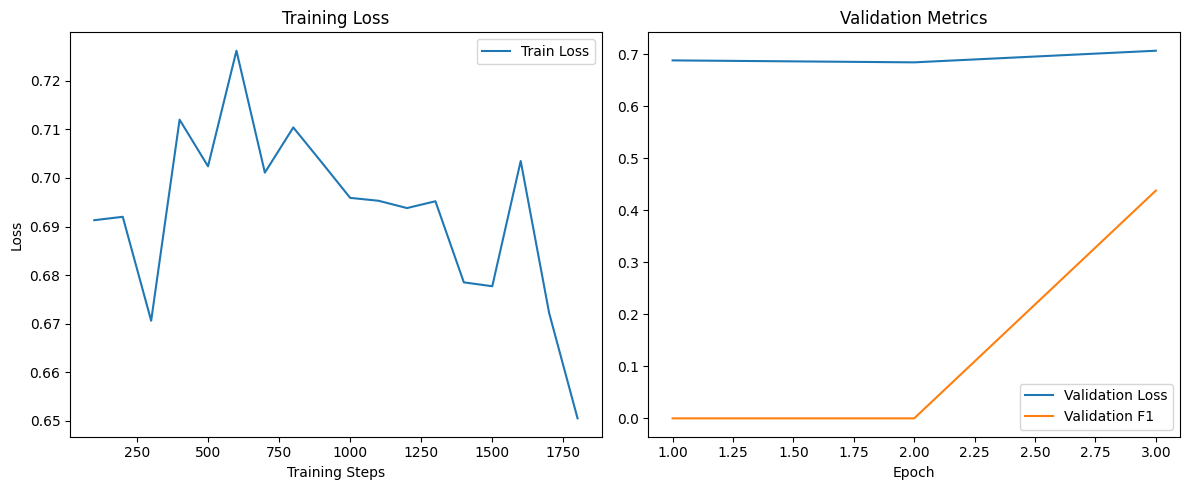


CONFRONTO FINALE

xlm-roberta-base:
  Accuracy: 0.7217
  F1-Score: 0.4377


In [1]:
import torch
from torch.utils.data import Dataset, DataLoader
from transformers import (
    AutoTokenizer, 
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    EarlyStoppingCallback
)
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, precision_recall_fscore_support
import json
import numpy as np
import pandas as pd
from sklearn.utils.class_weight import compute_class_weight
from transformers import TrainerCallback
import matplotlib.pyplot as plt


class TrainingStatsCallback(TrainerCallback):
    def __init__(self):
        self.train_loss = []
        self.eval_loss = []
        self.eval_f1 = []

    def on_log(self, args, state, control, logs=None, **kwargs):
        if logs is None:
            return
        if "loss" in logs:
            self.train_loss.append((state.global_step, logs["loss"]))
        if "eval_loss" in logs:
            self.eval_loss.append((state.epoch, logs["eval_loss"]))
        if "eval_f1" in logs:
            self.eval_f1.append((state.epoch, logs["eval_f1"]))

# 1. Caricamento del dataset
def load_dataset(file_path, language='en', dataset_name='MultiPICo', limit=None):
    """
    Carica il dataset dal unified corpus
    
    Args:
        file_path: percorso del file unified_corpus.json
        language: lingua da filtrare (default: 'en')
        dataset_name: nome del dataset da filtrare (default: 'MultiPICo')
        limit: numero massimo di entries da usare (None = tutte)
    
    Returns:
        DataFrame filtrato
    """
    try:
        with open(file_path, 'r', encoding='utf-8') as f:
            unified_corpus = json.load(f)
        print(f"Loaded unified corpus with {len(unified_corpus)} entries")
        
        df = pd.DataFrame(unified_corpus)
        
        # Filtra per lingua e dataset
        df_filtered = df[(df['language'] == language) & (df['dataset_name'] == dataset_name)]
        print(f"Filtered {dataset_name} {language.upper()} entries: {len(df_filtered)}")
        
        # Limita il numero di entries se specificato
        if limit is not None:
            df_filtered = df_filtered.head(limit)
            print(f"Using {len(df_filtered)} entries (limited)")
        
        return df_filtered
        
    except Exception as e:
        print(f"Error loading unified corpus: {e}")
        raise e

class CustomTrainer(Trainer):
    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        logits = outputs.logits

        # class weights dal config (converti in tensor)
        weight = getattr(model.config, "class_weight", None)
        if weight is not None:
            weight = torch.tensor(weight, dtype=torch.float, device=logits.device)

        loss_fct = torch.nn.CrossEntropyLoss(weight=weight)
        loss = loss_fct(logits, labels)

        return (loss, outputs) if return_outputs else loss

# 2. Classe Dataset personalizzata
class ConspiracyDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_length=512):
        self.texts = texts
        self.labels = labels
        self.tokenizer = tokenizer
        self.max_length = max_length
    
    def __len__(self):
        return len(self.texts)
    
    def __getitem__(self, idx):
        text = str(self.texts[idx])
        label = self.labels[idx]
        
        encoding = self.tokenizer(
            text,
            add_special_tokens=True,
            max_length=self.max_length,
            padding='max_length',
            truncation=True,
            return_tensors='pt'
        )
        
        return {
            'input_ids': encoding['input_ids'].flatten(),
            'attention_mask': encoding['attention_mask'].flatten(),
            'labels': torch.tensor(label, dtype=torch.long)
        }

# 3. Metriche di valutazione
def compute_metrics(pred):
    labels = pred.label_ids
    preds = pred.predictions.argmax(-1)
    
    precision, recall, f1, _ = precision_recall_fscore_support(
        labels, preds, average='binary'
    )
    acc = accuracy_score(labels, preds)
    
    return {
        'accuracy': acc,
        'f1': f1,
        'precision': precision,
        'recall': recall
    }

# 4. Funzione principale di training
def train_model(model_name, train_texts, train_labels, val_texts, val_labels, 
                output_dir, num_epochs=3, batch_size=4, learning_rate=2e-5):
    
    print(f"\n{'='*50}")
    print(f"Training: {model_name}")
    print(f"{'='*50}\n")
    

    class_weights = compute_class_weight(
        class_weight='balanced',
        classes=np.unique(train_labels),
        y=train_labels
    )

    class_weights = torch.tensor(class_weights, dtype=torch.float)
    print("Class Weights:", class_weights)

    # Carica tokenizer e modello
    tokenizer = AutoTokenizer.from_pretrained(model_name, trust_remote_code=True)
    print(f"Tokenizer {model_name} loaded.")
    model = AutoModelForSequenceClassification.from_pretrained(
        model_name,
        num_labels=2,
        problem_type="single_label_classification",
        trust_remote_code=True
    )
    model.gradient_checkpointing_enable()
    # ✅ Applica class weights come lista float
    model.config.class_weight = class_weights.cpu().tolist()
    print(f"Model {model_name} loaded.")
    
    # Crea i dataset
    train_dataset = ConspiracyDataset(train_texts, train_labels, tokenizer)
    val_dataset = ConspiracyDataset(val_texts, val_labels, tokenizer)
    print("Datasets created.")
    
    # Configura i parametri di training
    training_args = TrainingArguments(
        output_dir=output_dir,
        num_train_epochs=num_epochs,
        per_device_train_batch_size=batch_size,
        per_device_eval_batch_size=batch_size,
        learning_rate=learning_rate,
        weight_decay=0.01,
        logging_dir=f'{output_dir}/logs',
        logging_steps=100,
        eval_strategy="epoch",
        save_strategy="epoch",
        load_best_model_at_end=True,
        metric_for_best_model="f1",
        greater_is_better=True,
        warmup_steps=500,
        fp16=torch.cuda.is_available(),
        report_to="none"
    )
    print("Training arguments set.")
    
    # Inizializza il Trainer
    stats_callback = TrainingStatsCallback()

    trainer = CustomTrainer(
        model=model,
        args=training_args,
        train_dataset=train_dataset,
        eval_dataset=val_dataset,
        compute_metrics=compute_metrics,
        callbacks=[EarlyStoppingCallback(early_stopping_patience=2), stats_callback]
    )

    print("Trainer initialized.")
    
    # Training
    trainer.train()
    
    # Valutazione finale
    results = trainer.evaluate()
    print(f"\nRisultati finali per {model_name}:")
    print(f"Accuracy: {results['eval_accuracy']:.4f}")
    print(f"F1-Score: {results['eval_f1']:.4f}")
    print(f"Precision: {results['eval_precision']:.4f}")
    print(f"Recall: {results['eval_recall']:.4f}")

    # === Grafico ===
    steps, train_losses = zip(*stats_callback.train_loss)
    epochs_eval_loss = [x[0] for x in stats_callback.eval_loss]
    eval_losses = [x[1] for x in stats_callback.eval_loss]
    epochs_eval_f1 = [x[0] for x in stats_callback.eval_f1]
    eval_f1_scores = [x[1] for x in stats_callback.eval_f1]

    plt.figure(figsize=(12, 5))

    # Train Loss
    plt.subplot(1, 2, 1)
    plt.plot(steps, train_losses, label="Train Loss")
    plt.xlabel("Training Steps")
    plt.ylabel("Loss")
    plt.title("Training Loss")
    plt.legend()

    # Eval Loss + F1
    plt.subplot(1, 2, 2)
    plt.plot(epochs_eval_loss, eval_losses, label="Validation Loss")
    plt.plot(epochs_eval_f1, eval_f1_scores, label="Validation F1")
    plt.xlabel("Epoch")
    plt.title("Validation Metrics")
    plt.legend()

    plt.tight_layout()
    plt.show()
    
    # Salva il modello
    trainer.save_model(output_dir)
    tokenizer.save_pretrained(output_dir)
    
    return trainer, results


# 5. Script principale
# Carica i dati dal unified corpus
data_path = "../1_datasets_merge/output/unified_corpus.json"

# Carica e filtra il dataset
df = load_dataset(
    file_path=data_path,
    language='en',
    dataset_name='MultiPICo',
    limit=None  # None per usare tutti i dati, oppure un numero specifico per test
)

# Verifica che il DataFrame abbia le colonne necessarie
print(f"\nColonne disponibili: {df.columns.tolist()}")

# Adatta i nomi delle colonne al tuo dataset
# Assumo che ci siano colonne 'reply' e 'label'
# Se hanno nomi diversi, modifica qui:
text_column = 'reply'  # Modifica se necessario

df["label"] = df["annotations"].apply(lambda x: x.get("irony_appropriateness_label"))
label_column = "label"

if text_column not in df.columns or label_column not in df.columns:
    raise ValueError(f"Colonne richieste non trovate. Disponibili: {df.columns.tolist()}")

# Estrai testi e label
texts = df[text_column].tolist()
labels = df[label_column].tolist()

# Verifica la distribuzione delle label
print(f"\nDistribuzione label totali:")
print(pd.Series(labels).value_counts())

# Split train/validation (80/20)
train_texts, val_texts, train_labels, val_labels = train_test_split(
    texts, labels, test_size=0.2, random_state=42, stratify=labels
)

print(f"\nTraining samples: {len(train_texts)}")
print(f"Validation samples: {len(val_texts)}")
print(f"Label distribution - Train: {np.bincount(train_labels)}")
print(f"Label distribution - Val: {np.bincount(val_labels)}")

# Definisci i modelli da addestrare
models = {
    #"eurobert": "EuroBERT/EuroBERT-210m",
    "xlm-roberta-base": "FacebookAI/xlm-roberta-base"
}

results_all = {}

# Training per ogni modello
for model_short_name, model_full_name in models.items():
    output_dir = f"./models/{model_short_name}_finetuned"
    
    trainer, results = train_model(
        model_name=model_full_name,
        train_texts=train_texts,
        train_labels=train_labels,
        val_texts=val_texts,
        val_labels=val_labels,
        output_dir=output_dir,
        num_epochs=3,
        batch_size=4,  # Riduci se hai problemi di memoria
        learning_rate=2e-5
    )
    
    results_all[model_short_name] = results

# Confronto finale
print("\n" + "="*50)
print("CONFRONTO FINALE")
print("="*50)
for model_name, results in results_all.items():
    print(f"\n{model_name}:")
    print(f"  Accuracy: {results['eval_accuracy']:.4f}")
    print(f"  F1-Score: {results['eval_f1']:.4f}")